## Assignment problem statement 22


Group 153

| SL.NO | BITS ID      | NAME                      | CONTRIBUTION |
|-------|-------------|---------------------------|--------------|
| 1     | 2024AA05731 | Suraj Anand               | 20%          |
| 2     | 2024AA05732 | Ashvini Satish Bhosale    | 20%          |
| 3     | 2024AA05733 | Bollam Manindra           | 20%          |
| 4     | 2024AA05734 | S. Hari Chandana          | 20%          |
| 5     | 2024AA05735 | Nikhil Yadav              | 20%          |





## Importing Required Libraries




In [33]:
!pip install pandas numpy matplotlib seaborn nltk wordcloud scikit-learn gensim

import pandas as pd
import seaborn as sns
import numpy as np
import re
import string
#Accessing all NLP tools: tokenization, stop words, tagging, etc.
import nltk
import matplotlib.pyplot as plt
#Generating a word cloud from text data.
from wordcloud import WordCloud
#Splitting the data into training and test sets.
from sklearn.model_selection import train_test_split
#Training a simple classification model.
from sklearn.tree import DecisionTreeClassifier
#Evaluating model performance using a confusion matrix.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
#Getting a list of common English stopwords
from nltk.corpus import stopwords
#Lemmatization – converting words to their base (dictionary) form.
from nltk.stem import WordNetLemmatizer
from gensim.models import Word2Vec
# POS (Part-of-Speech) tagging using HMM
from nltk import pos_tag



In [34]:
# Step 0: Downloading NLTK specific modules
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('omw-1.4')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

## 1) Loading Financial Sentiment Analysis Dataset


In [35]:
file_id='15Wmi3GyCeEX6w8N528S40OYCnRhInH5W'
url = f'https://drive.google.com/uc?id={file_id}'
fsa = pd.read_csv(url)


fsa = pd.read_csv(url)

print(fsa.head())
print(fsa.info())
print(fsa.describe())

                                            Sentence Sentiment
0  The GeoSolutions technology will leverage Bene...  positive
1  $ESI on lows, down $1.50 to $2.50 BK a real po...  negative
2  For the last quarter of 2010 , Componenta 's n...  positive
3  According to the Finnish-Russian Chamber of Co...   neutral
4  The Swedish buyout firm has sold its remaining...   neutral
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5842 entries, 0 to 5841
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Sentence   5842 non-null   object
 1   Sentiment  5842 non-null   object
dtypes: object(2)
memory usage: 91.4+ KB
None
                                                 Sentence Sentiment
count                                                5842      5842
unique                                               5322         3
top     Managing Director 's comments : `` Net sales f...   neutral
freq                                      

# 2) & 3) Preprocessing the data(Removing punctuations, numbers and stop words; Lemmatizing)


In [36]:
stopwords_extract = set(stopwords.words("english"))
lemmatizerObj = WordNetLemmatizer()


def pre_process(sentence):
    sentence = str(sentence).lower()
    sentence = re.sub(r'[^a-z\s]', '', sentence)
    tokens_extract = nltk.word_tokenize(sentence)
    tokens_wo_stopwords = [word for word in tokens_extract if word not in stopwords_extract]
    tokens_result = [lemmatizerObj.lemmatize(word) for word in tokens_wo_stopwords]
    return " ".join(tokens_result)

fsa['cleaned_sentence'] = fsa['Sentence'].apply(pre_process)
print(fsa['cleaned_sentence'])

0       geosolutions technology leverage benefon gps s...
1                             esi low bk real possibility
2       last quarter componenta net sale doubled eurm ...
3       according finnishrussian chamber commerce majo...
4       swedish buyout firm sold remaining percent sta...
                              ...                        
5837    rising cost forced packaging producer huhtamak...
5838    nordic walking first used summer training meth...
5839    according shipping company viking line eu deci...
5840    building home improvement trade sale decreased...
5841    helsinki afx kci konecranes said order four ho...
Name: cleaned_sentence, Length: 5842, dtype: object


# 4) Forming the Word Cloud


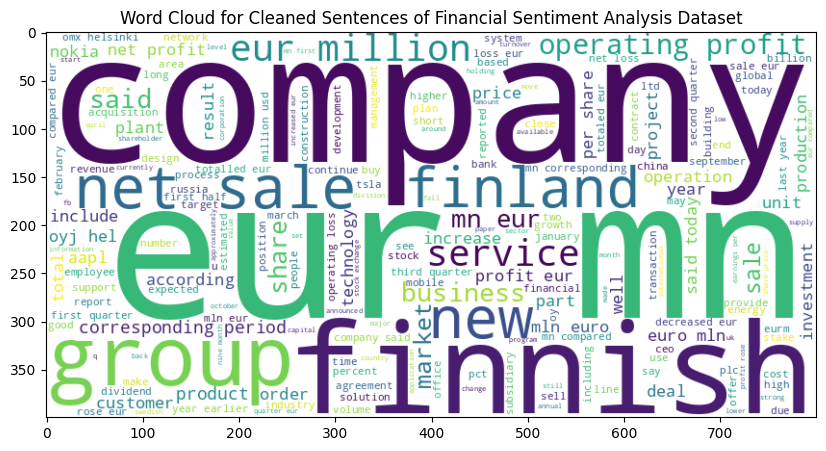

In [37]:
all_sentences = " ".join(fsa['cleaned_sentence'])
wordcloud_formed = WordCloud(width=800, height=400, background_color='white').generate(all_sentences)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_formed, interpolation='bilinear')
plt.axis("on") #for better scaling of wordcloud
plt.title("Word Cloud for Cleaned Sentences of Financial Sentiment Analysis Dataset")
plt.show()

# 5) Define X and Y for plotting


In [38]:
X = fsa['cleaned_sentence']
Y = fsa['Sentiment']

# 5A: Skip-gram Model with Decision Tree


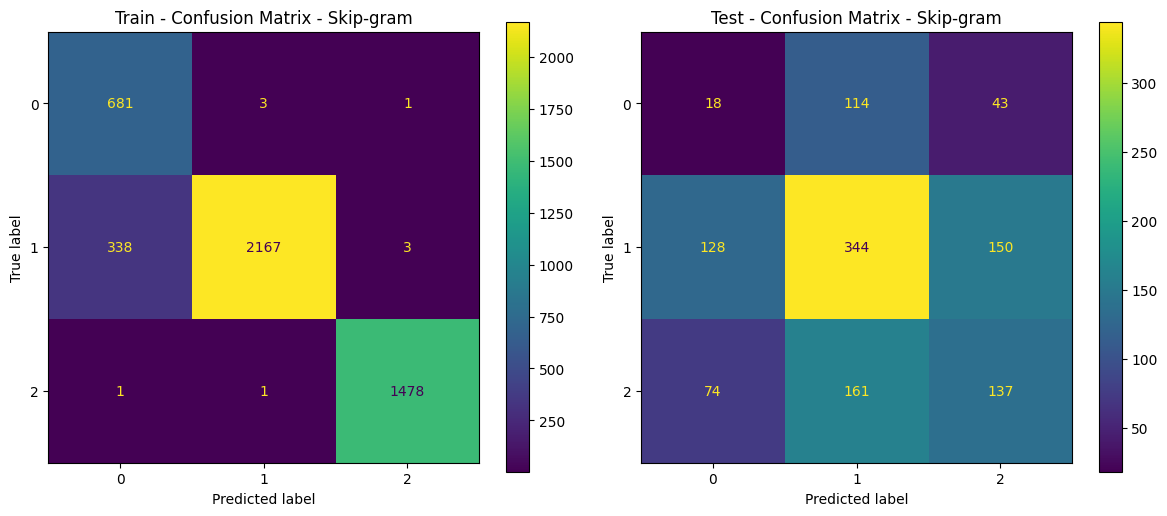

In [39]:
tokens_extract = [nltk.word_tokenize(sentence) for sentence in X]
skip_gram_model = Word2Vec(tokens_extract, vector_size=100, window=5, sg=1, min_count=1)

# Forming sentence embeddings
def embed_sentence(sentence, model):
    tokens_extract = nltk.word_tokenize(sentence)
    vectors = [model.wv[word] for word in tokens_extract if word in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)

# Defining train and test percentge in dataset
X_skip_gram_embed = np.array([embed_sentence(sent, skip_gram_model) for sent in X])
X_train, X_test, y_train, y_test = train_test_split(X_skip_gram_embed, Y, test_size=0.2, random_state=42)

# Decision Tree classifier
classifier_skip_gram = DecisionTreeClassifier()
classifier_skip_gram.fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Train - Confusion Matrix - Skip-gram
pred_sg_train = classifier_skip_gram.predict(X_train)
cm_sg_train = confusion_matrix(y_train, pred_sg_train)
cm_sg_train_obj = ConfusionMatrixDisplay(confusion_matrix=cm_sg_train)
cm_sg_train_obj.plot(ax=axes[0], values_format='d')
axes[0].set_title("Train - Confusion Matrix - Skip-gram")


# Test - Confusion Matrix - Skip-gram
pred_sg_test = classifier_skip_gram.predict(X_test)
cm_sg_test = confusion_matrix(y_test, pred_sg_test)
cm_sg_test_obj = ConfusionMatrixDisplay(confusion_matrix=cm_sg_test)
cm_sg_test_obj.plot(ax=axes[1], values_format='d')
axes[1].set_title("Test - Confusion Matrix - Skip-gram")
plt.tight_layout()
plt.show()



# 5B: CBoW Model with Decision Tree


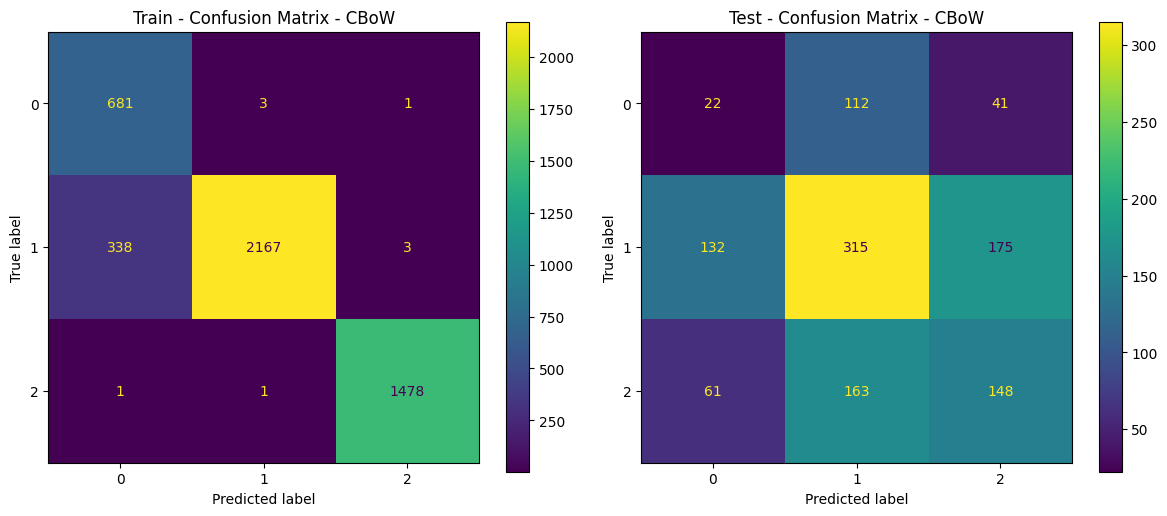

In [40]:
cbow_model = Word2Vec(tokens_extract, vector_size=100, window=5, sg=0, min_count=1)

# Defining train and test percentge in dataset
X_cbow_embed = np.array([embed_sentence(sent, cbow_model) for sent in X])
X_train, X_test, y_train, y_test = train_test_split(X_cbow_embed, Y, test_size=0.2, random_state=42)

# Decision Tree classifier
classifier_cbow = DecisionTreeClassifier()
classifier_cbow.fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Train Confusion Matrix - CBoW
pred_cbow_train = classifier_cbow.predict(X_train)
cm_cbow_train = confusion_matrix(y_train, pred_cbow_train)
cm_cbow_train_obj = ConfusionMatrixDisplay(confusion_matrix=cm_cbow_train)
cm_cbow_train_obj.plot(ax=axes[0], values_format='d')
axes[0].set_title("Train - Confusion Matrix - CBoW")

# Test Confusion Matrix - CBoW
pred_cbow_test = classifier_cbow.predict(X_test)
cm_cbow_test = confusion_matrix(y_test, pred_cbow_test)
cm_cbow_test_obj = ConfusionMatrixDisplay(confusion_matrix=cm_cbow_test)
cm_cbow_test_obj.plot(ax=axes[1], values_format='d')
axes[1].set_title("Test - Confusion Matrix - CBoW")
plt.tight_layout()
plt.show()

# 5C: Compare Skip-gram and CBow.


In this assignment, we trained both models on the financial sentiment data. Here's how they compare:

**A. Skip-gram**
* **Mechanism:** Skip-gram tries to predict the context words based on a single input word.
    
* **Strengths:** It tends to perform better with smaller datasets and can learn useful embeddings even for rare words.
* **Observation in our case:** We observed that Skip-gram captured some subtle financial terms better, which is important for domain-specific sentiment analysis.

**B. CBOW (Continuous Bag of Words)**
* **Mechanism:** CBOW works in the opposite way — it tries to predict a target word based on its context.
    
* **Strengths:** It is generally faster to train and performs well on larger, balanced datasets.
* **Observation in our case:** However, in our case, it occasionally missed nuances in less frequent financial terminology.

**Conclusion:**

Overall, while CBOW was faster, Skip-gram provided slightly better performance for our specific use case, which involved specialized vocabulary. For sentiment tasks in niche domains like finance, Skip-gram is preferable despite its higher training time.

# Step 6: HMM POS Tagging


In [41]:
first_cleaned = fsa['cleaned_sentence'].iloc[0]
tokens = nltk.word_tokenize(first_cleaned)
pos_tags = pos_tag(tokens)
print("POS Tagging for first cleaned_sentence:")
for i in pos_tags:
    print(i)

POS Tagging for first cleaned_sentence:
('geosolutions', 'NNS')
('technology', 'NN')
('leverage', 'NN')
('benefon', 'VBD')
('gps', 'JJ')
('solution', 'NN')
('providing', 'VBG')
('location', 'NN')
('based', 'VBN')
('search', 'NN')
('technology', 'NN')
('community', 'NN')
('platform', 'NN')
('location', 'NN')
('relevant', 'JJ')
('multimedia', 'NN')
('content', 'JJ')
('new', 'JJ')
('powerful', 'JJ')
('commercial', 'JJ')
('model', 'NN')
